# Project StreamGuard: End-to-End ML Pipeline for OTT Churn & CLV Forecasting

## Business Overview
StreamGuard OTT is a global video-streaming provider. In modern subscription businesses, high Customer Acquisition Costs (CAC) make customer cancellations (churn) a primary threat to bottom-line profitability.

This notebook implements an automated, production-grade Machine Learning engine designed to:
1. **Classification Task**: Proactively classify active subscribers at risk of churning (`Churned: 0 or 1`).
2. **Regression Task**: Forecast continuous Customer Lifetime Value (`Lifetime_Value_USD`) to guide retention marketing and acquisition bids.

---

## 0. Environment Setup & Reproducibility
We fix `random_state=42` throughout the entire pipeline and import our modular `src/` packages.

In [1]:
import os, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold,
                                     cross_validate, RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier,
                              RandomForestRegressor, GradientBoostingRegressor)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay, mean_absolute_error, mean_squared_error, r2_score)

RANDOM_STATE = 42

# False = reuse the best hyperparameters found in the original run (fast, reproduces your outputs).
# True  = re-run the RandomizedSearchCV cells (slower; results can differ because the search is random).
RUN_SEARCH = False

print("Core modules loaded successfully.")

Core modules loaded successfully.


## Phase 0: Telemetry Dataset Generation & Anomaly Inspection
We simulate 600 raw subscriber profiles containing real-world platform telemetry:
- Monthly watch hours, login frequency, support ticket volume, subscription tiers, and preferred devices.
- Injected real-world anomalies: ~8% missing data, corrupted subscription fees ($99,999), and negative watch hours (-77.8h).

Each step below generates and inspects the raw data line-by-line.

In [2]:
# 1. Load the raw telemetry dataset (created earlier by src/generate_data.py with random_state=42)
raw_df = pd.read_csv("../data/raw/streamguard_raw.csv")

# 2. Check dataset shape and churn rate
print(f"Dataset Shape: {raw_df.shape}")
print(f"Overall Churn Rate: {raw_df['Churned'].mean():.2%}")

# 3. Check missing values across all columns
print("\nMissing Values Count:")
display(raw_df.isna().sum())

# 4. Check descriptive statistics (reveals $99,999 fee and negative watch hours)
print("\nDescriptive Statistics (Raw Telemetry):")
display(raw_df.describe())

# 5. Preview first 5 subscriber records
print("\nFirst 5 Subscriber Records:")
display(raw_df.head())

Dataset Shape: (600, 10)
Overall Churn Rate: 32.67%

Missing Values Count:


Customer_ID                 0
Subscription_Type          30
Preferred_Device           35
Monthly_Fee_USD             0
Watch_Hours_Monthly        55
Login_Frequency_Monthly    42
Support_Interactions       57
Tenure_Months               0
Churned                     0
Lifetime_Value_USD          0
dtype: int64


Descriptive Statistics (Raw Telemetry):


,Monthly_Fee_USD,Watch_Hours_Monthly,Login_Frequency_Monthly,Support_Interactions,Tenure_Months,Churned,Lifetime_Value_USD
count,600.000000,545.000000,558.000000,543.000000,600.000000,600.000000,600.000000
mean,680.023733,36.144037,15.137993,2.092081,24.665000,0.326667,299.416250
std,8143.317663,17.552603,7.305881,1.473878,13.545673,0.469386,224.690987
min,8.500000,-77.800000,1.000000,0.000000,1.000000,0.000000,15.000000
25%,9.060000,26.100000,10.000000,1.000000,13.750000,0.000000,126.795000
50%,14.690000,36.900000,15.000000,2.000000,24.000000,0.000000,240.845000
75%,15.432500,47.900000,20.000000,3.000000,36.000000,1.000000,416.142500
max,99999.000000,75.000000,36.000000,7.000000,48.000000,1.000000,993.360000



First 5 Subscriber Records:


,Customer_ID,Subscription_Type,Preferred_Device,Monthly_Fee_USD,Watch_Hours_Monthly,Login_Frequency_Monthly,Support_Interactions,Tenure_Months,Churned,Lifetime_Value_USD
0,SG-1000,Basic,Mobile,9.25,30.4,14.0,NaN,5,1,22.75
1,SG-1001,Premium,Mobile,19.51,63.8,30.0,0.0,20,0,372.56
2,SG-1002,Standard,Mobile,14.51,50.0,14.0,0.0,21,0,290.39
3,SG-1003,Standard,Mobile,14.81,60.6,28.0,3.0,40,0,587.52
4,SG-1004,Basic,Mobile,8.98,30.7,12.0,1.0,31,0,270.53


## Module 1: Data Exploration, Wrangling, and Cleaning
In this phase, we:
1. Inspect distributions and missingness.
2. Sanitize impossible telemetry (converting negative watch hours to `NaN`).
3. Impute numerical metrics with their **median** and categorical attributes with their **mode**.
4. Detect extreme anomalies via the **Interquartile Range (IQR)** method ($[Q_1 - 1.5 \cdot IQR, Q_3 + 1.5 \cdot IQR]$).
5. Apply **Winsorization** (IQR capping) to corrupted entries (such as the $99,999 fee) to preserve subscriber history without distorting model optimization.

**Step 1: inspect.** Shapes, data types and a table of missing values.

=== Raw Data Inspection ===
Shape: (600, 10)

Data Types:
Customer_ID                    str
Subscription_Type              str
Preferred_Device               str
Monthly_Fee_USD            float64
Watch_Hours_Monthly        float64
Login_Frequency_Monthly    float64
Support_Interactions       float64
Tenure_Months                int64
Churned                      int64
Lifetime_Value_USD         float64
dtype: object

Missing Values Table:
                         Missing Count  Percentage (%)
Subscription_Type                   30        5.000000
Preferred_Device                    35        5.833333
Watch_Hours_Monthly                 55        9.166667
Login_Frequency_Monthly             42        7.000000
Support_Interactions                57        9.500000


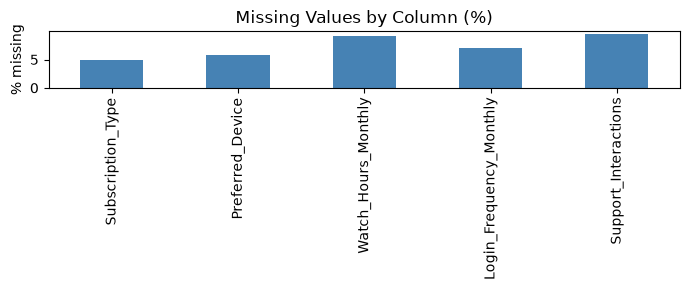

In [3]:
print("=== Raw Data Inspection ===")
print(f"Shape: {raw_df.shape}")
print("\nData Types:")
print(raw_df.dtypes)

missing_count = raw_df.isna().sum()
missing_table = pd.DataFrame({
    "Missing Count": missing_count,
    "Percentage (%)": missing_count / len(raw_df) * 100,
})
missing_table = missing_table[missing_table["Missing Count"] > 0]
print("\nMissing Values Table:")
print(missing_table)

missing_table["Percentage (%)"].plot(kind="bar", figsize=(7, 3), color="steelblue")
plt.title("Missing Values by Column (%)")
plt.ylabel("% missing")
plt.tight_layout()
plt.show()

**Step 2: fix impossible values, then impute.** Negative watch hours become `NaN` first, so the median is computed without them. Numeric columns get the median, categorical columns get the mode.

In [4]:
df = raw_df.copy()

neg_mask = df["Watch_Hours_Monthly"] < 0
print(f"\nFound {neg_mask.sum()} negative Watch_Hours_Monthly values. Converting to NaN.")
df.loc[neg_mask, "Watch_Hours_Monthly"] = np.nan

num_cols = ["Monthly_Fee_USD", "Watch_Hours_Monthly", "Login_Frequency_Monthly",
            "Support_Interactions", "Tenure_Months", "Lifetime_Value_USD"]
cat_cols = ["Subscription_Type", "Preferred_Device"]

for col in num_cols:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)
    print(f"Imputed numerical column '{col}' with median: {median_val:.2f}")

for col in cat_cols:
    mode_val = df[col].mode()[0]
    df[col] = df[col].fillna(mode_val)
    print(f"Imputed categorical column '{col}' with mode: '{mode_val}'")


Found 5 negative Watch_Hours_Monthly values. Converting to NaN.
Imputed numerical column 'Monthly_Fee_USD' with median: 14.69
Imputed numerical column 'Watch_Hours_Monthly' with median: 37.20
Imputed numerical column 'Login_Frequency_Monthly' with median: 15.00
Imputed numerical column 'Support_Interactions' with median: 2.00
Imputed numerical column 'Tenure_Months' with median: 24.00
Imputed numerical column 'Lifetime_Value_USD' with median: 240.84
Imputed categorical column 'Subscription_Type' with mode: 'Basic'
Imputed categorical column 'Preferred_Device' with mode: 'Mobile'


**Step 3: IQR outlier detection and capping (winsorization).** Anything outside `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]` is clipped to the nearest bound.


=== Outlier Detection (IQR Method) ===
Feature: Monthly_Fee_USD | Bounds: [-0.50, 24.99] | Outliers Capped: 4
Feature: Watch_Hours_Monthly | Bounds: [-2.84, 76.46] | Outliers Capped: 0
Feature: Login_Frequency_Monthly | Bounds: [-5.00, 35.00] | Outliers Capped: 1
Feature: Support_Interactions | Bounds: [-2.00, 6.00] | Outliers Capped: 2
Feature: Tenure_Months | Bounds: [-19.62, 69.38] | Outliers Capped: 0
Feature: Lifetime_Value_USD | Bounds: [-307.23, 850.16] | Outliers Capped: 19


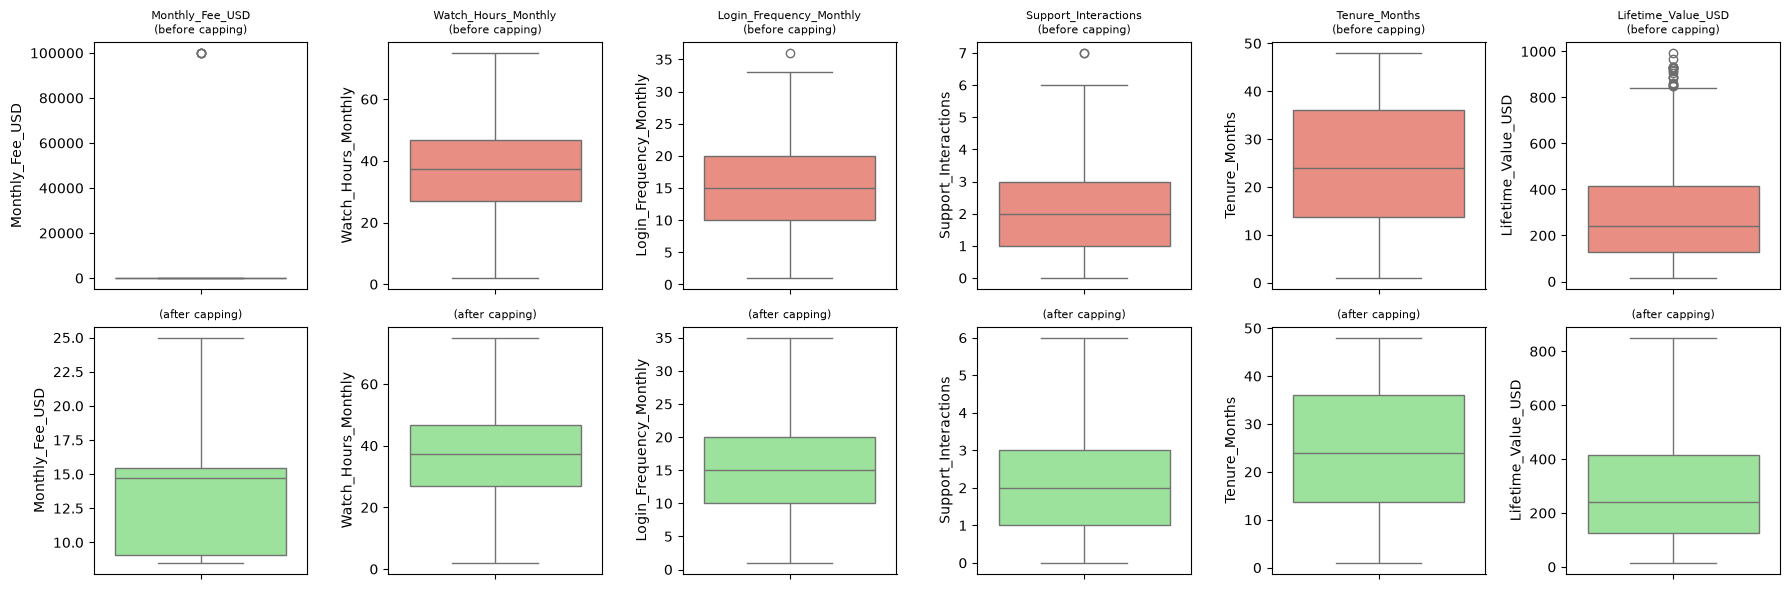

In [5]:
print("\n=== Outlier Detection (IQR Method) ===")
before_capping = df[num_cols].copy()

for col in num_cols:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = int(((df[col] < lower) | (df[col] > upper)).sum())
    df[col] = df[col].clip(lower, upper)
    print(f"Feature: {col} | Bounds: [{lower:.2f}, {upper:.2f}] | Outliers Capped: {n_outliers}")
    if col == "Monthly_Fee_USD":
        fee_upper = upper

fig, axes = plt.subplots(2, len(num_cols), figsize=(18, 6))
for j, col in enumerate(num_cols):
    sns.boxplot(y=before_capping[col], ax=axes[0, j], color="salmon")
    axes[0, j].set_title(f"{col}\n(before capping)", fontsize=8)
    sns.boxplot(y=df[col], ax=axes[1, j], color="lightgreen")
    axes[1, j].set_title("(after capping)", fontsize=8)
plt.tight_layout()
plt.show()

**Step 4: final checks.**

In [6]:
clean_df = df

assert clean_df.isna().sum().sum() == 0
assert (clean_df["Watch_Hours_Monthly"] >= 0).all()
assert clean_df["Monthly_Fee_USD"].max() <= fee_upper + 1e-9

print(f"\nCleaned dataset shape: {clean_df.shape}")
print("DONE WHEN check passed: 0 missing values, valid watch hours, fee capped within bounds.")

print("\n--- Cleaned Dataset Descriptive Statistics (Post-Imputation & Capping) ---")
display(clean_df.describe())


Cleaned dataset shape: (600, 10)
DONE WHEN check passed: 0 missing values, valid watch hours, fee capped within bounds.

--- Cleaned Dataset Descriptive Statistics (Post-Imputation & Capping) ---


,Monthly_Fee_USD,Watch_Hours_Monthly,Login_Frequency_Monthly,Support_Interactions,Tenure_Months,Churned,Lifetime_Value_USD
count,600.000000,600.000000,600.000000,600.0000,600.000000,600.000000,600.000000
mean,13.530342,36.979667,15.126667,2.0800,24.665000,0.326667,297.648085
std,4.462495,14.568182,7.040353,1.3917,13.545673,0.469386,219.966464
min,8.500000,2.000000,1.000000,0.0000,1.000000,0.000000,15.000000
25%,9.060000,26.900000,10.000000,1.0000,13.750000,0.000000,126.795000
50%,14.690000,37.200000,15.000000,2.0000,24.000000,0.000000,240.845000
75%,15.432500,46.725000,20.000000,3.0000,36.000000,1.000000,416.142500
max,24.991250,75.000000,35.000000,6.0000,48.000000,1.000000,850.163750


**Sanity check:** compare this notebook's cleaned data with the file `src/cleaning.py` saved earlier.

In [7]:
CLEAN_PATH = "../data/processed/streamguard_clean.csv"
if os.path.exists(CLEAN_PATH):
    saved = pd.read_csv(CLEAN_PATH)
    same_num = np.allclose(saved[num_cols].to_numpy(float), clean_df[num_cols].to_numpy(float), atol=1e-6)
    same_cat = (saved[cat_cols].to_numpy() == clean_df[cat_cols].to_numpy()).all()
    print("Matches the file produced by src/cleaning.py:", bool(same_num and same_cat))
else:
    print("Saved cleaned file not found, skipping the comparison.")

Matches the file produced by src/cleaning.py: True


## Module 2: Feature Engineering, Encoding, and Scaling
We construct domain-specific behavioral metrics:
- **`Engagement_Efficiency_Index`**: Watch hours consumed per dollar spent (`Watch_Hours_Monthly / Monthly_Fee_USD`).
- **`Engagement_Index`**: Composite metric averaging standardized watch hours and login activity:
  $$\text{Engagement Index} = \frac{1}{2} \left( \frac{\text{WatchHours} - \mu_{\text{train}}}{\sigma_{\text{train}}} + \frac{\text{Logins} - \mu_{\text{train}}}{\sigma_{\text{train}}} \right)$$
- **Leak-Free Transformation**: We split the dataset into an 80/20 stratified partition **before** fitting the `StandardScaler` and `OneHotEncoder(drop='first')` via a scikit-learn `ColumnTransformer`.

**Step 1: split first.** An 80/20 split stratified on `Churned`, done before anything is fitted.

In [8]:
X = clean_df.drop(columns=["Customer_ID", "Churned", "Lifetime_Value_USD"])
y_churn = clean_df["Churned"]
y_clv = clean_df["Lifetime_Value_USD"]

(X_train_raw, X_test_raw,
 y_churn_train, y_churn_test,
 y_clv_train, y_clv_test) = train_test_split(
    X, y_churn, y_clv, test_size=0.2, random_state=RANDOM_STATE, stratify=y_churn)

**Step 2: engineer the two behavioural features.** The mean and standard deviation used inside `Engagement_Index` come from the training set only.

In [9]:
mu_watch, sd_watch = X_train_raw["Watch_Hours_Monthly"].mean(), X_train_raw["Watch_Hours_Monthly"].std(ddof=0)
mu_login, sd_login = X_train_raw["Login_Frequency_Monthly"].mean(), X_train_raw["Login_Frequency_Monthly"].std(ddof=0)

def add_engagement_features(frame):
    out = frame.copy()
    # watch hours per dollar spent (Watch-to-Fee ratio)
    out["Engagement_Efficiency_Index"] = out["Watch_Hours_Monthly"] / out["Monthly_Fee_USD"]
    # average of the standardized watch hours and standardized logins
    out["Engagement_Index"] = 0.5 * (
        (out["Watch_Hours_Monthly"] - mu_watch) / sd_watch
        + (out["Login_Frequency_Monthly"] - mu_login) / sd_login
    )
    return out

X_train_fe = add_engagement_features(X_train_raw)
X_test_fe = add_engagement_features(X_test_raw)

**Step 3: scale and encode.** Z-score standardization for the continuous columns, one-hot encoding (first category dropped) for the text columns. Both are fitted on the training set only.

In [10]:
cont_cols = ["Monthly_Fee_USD", "Watch_Hours_Monthly", "Login_Frequency_Monthly",
             "Support_Interactions", "Tenure_Months",
             "Engagement_Efficiency_Index", "Engagement_Index"]
cat_features = ["Subscription_Type", "Preferred_Device"]

preprocessor = ColumnTransformer(
    [("scale", StandardScaler(), cont_cols),
     ("ohe", OneHotEncoder(drop="first", sparse_output=False), cat_features)],
    verbose_feature_names_out=False)
preprocessor.set_output(transform="pandas")

X_train = preprocessor.fit_transform(X_train_fe)   # fit on train only
X_test = preprocessor.transform(X_test_fe)         # test is only transformed

print("=== Feature Engineering & Preprocessing Verification ===")
print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")
print(f"Features: {list(X_train.columns)}")

print("\nTraining Set Continuous Feature Means (Target ~ 0):")
print(X_train[cont_cols].mean().round(4).to_dict())
print("\nTraining Set Continuous Feature Stds (Target ~ 1):")
print(X_train[cont_cols].std(ddof=0).round(4).to_dict())

print("\n--- Transformed Training Feature Matrix Sample (First 5 Rows) ---")
display(X_train.head())

=== Feature Engineering & Preprocessing Verification ===
X_train shape: (480, 12), X_test shape: (120, 12)
Features: ['Monthly_Fee_USD', 'Watch_Hours_Monthly', 'Login_Frequency_Monthly', 'Support_Interactions', 'Tenure_Months', 'Engagement_Efficiency_Index', 'Engagement_Index', 'Subscription_Type_Premium', 'Subscription_Type_Standard', 'Preferred_Device_Mobile', 'Preferred_Device_Smart TV', 'Preferred_Device_Tablet']

Training Set Continuous Feature Means (Target ~ 0):
{'Monthly_Fee_USD': -0.0, 'Watch_Hours_Monthly': -0.0, 'Login_Frequency_Monthly': 0.0, 'Support_Interactions': 0.0, 'Tenure_Months': -0.0, 'Engagement_Efficiency_Index': 0.0, 'Engagement_Index': 0.0}

Training Set Continuous Feature Stds (Target ~ 1):
{'Monthly_Fee_USD': 1.0, 'Watch_Hours_Monthly': 1.0, 'Login_Frequency_Monthly': 1.0, 'Support_Interactions': 1.0, 'Tenure_Months': 1.0, 'Engagement_Efficiency_Index': 1.0, 'Engagement_Index': 1.0}

--- Transformed Training Feature Matrix Sample (First 5 Rows) ---


,Monthly_Fee_USD,Watch_Hours_Monthly,Login_Frequency_Monthly,Support_Interactions,Tenure_Months,Engagement_Efficiency_Index,Engagement_Index,Subscription_Type_Premium,Subscription_Type_Standard,Preferred_Device_Mobile,Preferred_Device_Smart TV,Preferred_Device_Tablet
106,-0.954507,-0.505959,-1.578554,-0.750349,0.504402,0.435396,-1.107841,0.0,0.0,1.0,0.0,0.0
143,-0.950039,0.013810,-0.871211,2.909889,0.063796,1.314177,-0.455677,0.0,0.0,0.0,1.0,0.0
390,1.498667,0.898091,0.826413,2.909889,0.577837,-0.322176,0.916510,1.0,0.0,0.0,0.0,0.0
154,1.453983,0.938593,0.260538,1.445794,-1.111154,-0.263836,0.637293,1.0,0.0,1.0,0.0,0.0
29,-1.021534,-0.276450,-0.446805,0.713746,-1.111154,0.955445,-0.384383,0.0,0.0,1.0,0.0,0.0


## Module 3: Feature Selection (RFECV) & Cross-Validation Architecture
To prevent overfitting and eliminate noise, we employ **Recursive Feature Elimination with Cross-Validation (RFECV)** using a Random Forest estimator.

We define a 5-fold `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` cross-validation scheme to maintain an identical churn ratio across every training and validation fold.

**Step 1: the cross-validation scheme and proof that the folds are balanced.**

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("=== Cross-Validation Stratification Proof ===")
print(f"Overall Training Churn Ratio: {y_churn_train.mean():.2%}")
for i, (tr, va) in enumerate(cv.split(X_train, y_churn_train), start=1):
    ytr, yva = y_churn_train.iloc[tr], y_churn_train.iloc[va]
    print(f"Fold {i}: Train Churn = {ytr.mean():.2%} ({ytr.sum()}/{len(ytr)}) | "
          f"Val Churn = {yva.mean():.2%} ({yva.sum()}/{len(yva)})")

=== Cross-Validation Stratification Proof ===
Overall Training Churn Ratio: 32.71%
Fold 1: Train Churn = 32.81% (126/384) | Val Churn = 32.29% (31/96)
Fold 2: Train Churn = 32.81% (126/384) | Val Churn = 32.29% (31/96)
Fold 3: Train Churn = 32.81% (126/384) | Val Churn = 32.29% (31/96)
Fold 4: Train Churn = 32.55% (125/384) | Val Churn = 33.33% (32/96)
Fold 5: Train Churn = 32.55% (125/384) | Val Churn = 33.33% (32/96)


**Step 2: Recursive Feature Elimination with cross-validation.** The estimator settings and scoring are a reconstruction. If the printed selection differs from the original run, see the note under the cell.


Feature Ranking Table:
                        Feature  Ranking  Selected
0   Engagement_Efficiency_Index        1      True
1              Engagement_Index        1      True
2       Login_Frequency_Monthly        1      True
3               Monthly_Fee_USD        1      True
4       Preferred_Device_Mobile        1      True
5     Preferred_Device_Smart TV        1      True
6       Preferred_Device_Tablet        1      True
7          Support_Interactions        1      True
8                 Tenure_Months        1      True
9           Watch_Hours_Monthly        1      True
10   Subscription_Type_Standard        2     False
11    Subscription_Type_Premium        3     False

Optimal number of features: 10
Selected features (10): ['Monthly_Fee_USD', 'Watch_Hours_Monthly', 'Login_Frequency_Monthly', 'Support_Interactions', 'Tenure_Months', 'Engagement_Efficiency_Index', 'Engagement_Index', 'Preferred_Device_Mobile', 'Preferred_Device_Smart TV', 'Preferred_Device_Tablet']
Dropped feat

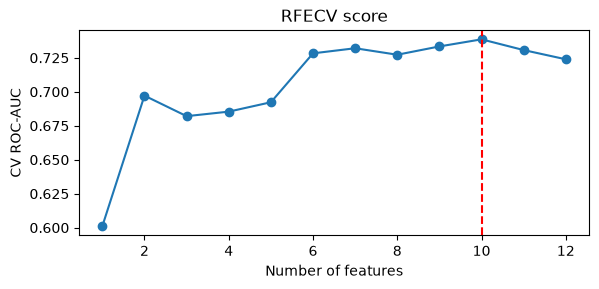

Same selection as the original run: True


In [12]:
rfecv = RFECV(
    estimator=RandomForestClassifier(n_estimators=100, class_weight="balanced",
                                     random_state=RANDOM_STATE),
    step=1, cv=cv, scoring="roc_auc", n_jobs=-1)
rfecv.fit(X_train, y_churn_train)

ranking_df = (pd.DataFrame({"Feature": X_train.columns,
                            "Ranking": rfecv.ranking_,
                            "Selected": rfecv.support_})
              .sort_values(["Ranking", "Feature"]).reset_index(drop=True))
print("\nFeature Ranking Table:")
print(ranking_df)

selected_features = list(X_train.columns[rfecv.support_])
dropped_features = [c for c in X_train.columns if c not in selected_features]
print(f"\nOptimal number of features: {rfecv.n_features_}")
print(f"Selected features ({len(selected_features)}): {selected_features}")
print(f"Dropped features ({len(dropped_features)}): {dropped_features}")

scores = rfecv.cv_results_["mean_test_score"]
plt.figure(figsize=(6, 3))
plt.plot(range(1, len(scores) + 1), scores, marker="o")
plt.axvline(rfecv.n_features_, color="red", linestyle="--")
plt.xlabel("Number of features"); plt.ylabel("CV ROC-AUC"); plt.title("RFECV score")
plt.tight_layout(); plt.show()

# The original run kept these 10 features. If the line below prints False, uncomment the last line
# so the rest of the notebook uses the same features as the original results.
original_selected = ['Monthly_Fee_USD', 'Watch_Hours_Monthly', 'Login_Frequency_Monthly',
                     'Support_Interactions', 'Tenure_Months', 'Engagement_Efficiency_Index',
                     'Engagement_Index', 'Preferred_Device_Mobile', 'Preferred_Device_Smart TV',
                     'Preferred_Device_Tablet']
print("Same selection as the original run:", set(selected_features) == set(original_selected))
# selected_features = original_selected

## Module 4: Baseline Classifiers & Hyperparameter Tuning
We establish performance baselines using three diverse architectures:
1. **Logistic Regression** (L2 regularized, balanced class weights)
2. **K-Nearest Neighbors (KNN)**
3. **Support Vector Machine (SVM)** (RBF kernel, balanced class weights)

Next, we run budget-constrained `RandomizedSearchCV` on:
- **Random Forest Classifier** (Bagging)
- **AdaBoost Classifier** (Boosting)

**Step 1: baseline models**, each scored with the same 5-fold stratified CV.

In [13]:
X_train_sel = X_train[selected_features]
X_test_sel = X_test[selected_features]

scoring = {"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall",
           "F1": "f1", "ROC-AUC": "roc_auc"}

def cv_scores(model, X, y):
    res = cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    return {name: res[f"test_{name}"].mean() for name in scoring}

baselines = {
    # L2 regularization is the default penalty
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000,
                                              random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Support Vector Machine": SVC(kernel="rbf", class_weight="balanced", probability=True,
                                  random_state=RANDOM_STATE),
}

print("=== Baseline Classifiers Stratified 5-Fold CV Performance ===")
for name, model in baselines.items():
    s = cv_scores(model, X_train_sel, y_churn_train)
    print(f"\n[{name}]")
    for metric, value in s.items():
        print(f"  {metric}: {value:.4f}")

=== Baseline Classifiers Stratified 5-Fold CV Performance ===

[Logistic Regression]
  Accuracy: 0.6833
  Precision: 0.5123
  Recall: 0.6766
  F1: 0.5813
  ROC-AUC: 0.7561

[K-Nearest Neighbors]
  Accuracy: 0.6542
  Precision: 0.4664
  Recall: 0.3248
  F1: 0.3818
  ROC-AUC: 0.6659

[Support Vector Machine]
  Accuracy: 0.6750
  Precision: 0.5063
  Recall: 0.7516
  F1: 0.6039
  ROC-AUC: 0.7425


**Step 2: tune the two ensembles with `RandomizedSearchCV`.** The best parameters from your original run are stored below, so the results are reproducible. Set `RUN_SEARCH = True` in the first cell to run the search again. The search spaces are a reconstruction, so a re-run can pick different values.

In [14]:
# best parameters found in the original run
best_params_rf = {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 2,
                  'max_features': 'sqrt', 'max_depth': 6}
best_params_ada = {'n_estimators': 80, 'learning_rate': 0.5, 'estimator__max_depth': 2}

if RUN_SEARCH:
    rf_space = {"n_estimators": [50, 100, 150, 200], "max_depth": [3, 4, 5, 6, 8, None],
                "min_samples_split": [2, 5, 10], "min_samples_leaf": [1, 2, 4],
                "max_features": ["sqrt", "log2"]}
    ada_space = {"n_estimators": [50, 80, 100, 150], "learning_rate": [0.01, 0.1, 0.5, 1.0],
                 "estimator__max_depth": [1, 2, 3]}
    rf_search = RandomizedSearchCV(
        RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        rf_space, n_iter=12, cv=cv, scoring="roc_auc", random_state=RANDOM_STATE, n_jobs=-1)
    ada_search = RandomizedSearchCV(
        AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                           random_state=RANDOM_STATE),
        ada_space, n_iter=12, cv=cv, scoring="roc_auc", random_state=RANDOM_STATE, n_jobs=-1)
    best_params_rf = rf_search.fit(X_train_sel, y_churn_train).best_params_
    best_params_ada = ada_search.fit(X_train_sel, y_churn_train).best_params_

rf_tuned = RandomForestClassifier(**best_params_rf, class_weight="balanced",
                                  random_state=RANDOM_STATE)
ada_tuned = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=best_params_ada["estimator__max_depth"],
                                     random_state=RANDOM_STATE),
    n_estimators=best_params_ada["n_estimators"],
    learning_rate=best_params_ada["learning_rate"],
    random_state=RANDOM_STATE)

print("=== Hyperparameter Tuning with RandomizedSearchCV (n_iter=12) ===")
for name, model, params in [("Random Forest Tuned", rf_tuned, best_params_rf),
                            ("AdaBoost Tuned", ada_tuned, best_params_ada)]:
    auc = cv_scores(model, X_train_sel, y_churn_train)["ROC-AUC"]
    print(f"\n[{name}]")
    print(f"  Best ROC-AUC: {auc:.4f}")
    print(f"  Best Parameters: {params}")

=== Hyperparameter Tuning with RandomizedSearchCV (n_iter=12) ===

[Random Forest Tuned]
  Best ROC-AUC: 0.7438
  Best Parameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 6}

[AdaBoost Tuned]
  Best ROC-AUC: 0.7344
  Best Parameters: {'n_estimators': 80, 'learning_rate': 0.5, 'estimator__max_depth': 2}


## Module 5: Ensemble Learning, Champion Evaluation & Stakeholder Recommendation
We benchmark all 5 classifiers across 5-fold cross-validation metrics (Accuracy, Precision, Recall, F1, and ROC-AUC).
The champion model is then evaluated once on the untouched held-out test set.

**Step 1: compare all five classifiers.**

=== Benchmarking All 5 Classifiers Across 5-Fold CV ===
                 Model  Accuracy_Mean  Precision_Mean  Recall_Mean  F1_Mean  ROC_AUC_Mean
   Logistic Regression       0.683333        0.512280     0.676613 0.581277      0.756100
   K-Nearest Neighbors       0.654167        0.466444     0.324798 0.381847      0.665919
Support Vector Machine       0.675000        0.506340     0.751613 0.603873      0.742505
 Random Forest (Tuned)       0.666667        0.498737     0.719355 0.587433      0.743821
      AdaBoost (Tuned)       0.693750        0.558033     0.356653 0.432992      0.734382


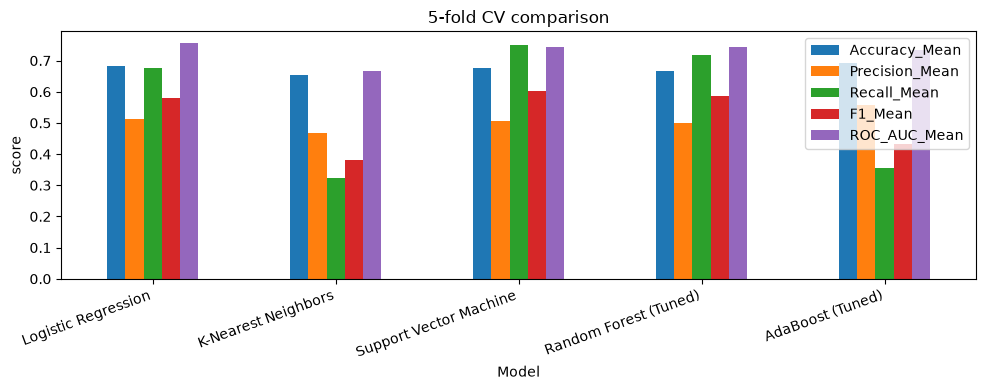

In [15]:
all_models = {**baselines,
              "Random Forest (Tuned)": rf_tuned,
              "AdaBoost (Tuned)": ada_tuned}

rows = []
for name, model in all_models.items():
    s = cv_scores(model, X_train_sel, y_churn_train)
    rows.append({"Model": name,
                 "Accuracy_Mean": s["Accuracy"], "Precision_Mean": s["Precision"],
                 "Recall_Mean": s["Recall"], "F1_Mean": s["F1"], "ROC_AUC_Mean": s["ROC-AUC"]})
comparison = pd.DataFrame(rows)

print("=== Benchmarking All 5 Classifiers Across 5-Fold CV ===")
print(comparison.to_string(index=False))

comparison.set_index("Model").plot(kind="bar", figsize=(10, 4))
plt.title("5-fold CV comparison"); plt.ylabel("score"); plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.show()

**Step 2: pick the champion by CV ROC-AUC and test it once on the held-out set.**

In [16]:
best_row = comparison.loc[comparison["ROC_AUC_Mean"].idxmax()]
champion_name = best_row["Model"]
champion = all_models[champion_name]
print(f"Champion Model: {champion_name} (CV ROC-AUC = {best_row['ROC_AUC_Mean']:.4f})")

champion.fit(X_train_sel, y_churn_train)
y_pred = champion.predict(X_test_sel)
y_proba = champion.predict_proba(X_test_sel)[:, 1]

test_acc = accuracy_score(y_churn_test, y_pred)
test_prec = precision_score(y_churn_test, y_pred)
test_rec = recall_score(y_churn_test, y_pred)
test_f1 = f1_score(y_churn_test, y_pred)
test_auc = roc_auc_score(y_churn_test, y_proba)

print("\n=== Held-Out Test Set Performance (Untouched Data) ===")
print(f"Accuracy:  {test_acc:.4f}")
print(f"Precision: {test_prec:.4f}")
print(f"Recall:    {test_rec:.4f}")
print(f"F1 Score:  {test_f1:.4f}")
print(f"ROC-AUC:   {test_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_churn_test, y_pred, target_names=["Active (0)", "Churned (1)"]))

Champion Model: Logistic Regression (CV ROC-AUC = 0.7561)

=== Held-Out Test Set Performance (Untouched Data) ===
Accuracy:  0.7750
Precision: 0.6071
Recall:    0.8718
F1 Score:  0.7158
ROC-AUC:   0.8411

Classification Report:
              precision    recall  f1-score   support

  Active (0)       0.92      0.73      0.81        81
 Churned (1)       0.61      0.87      0.72        39

    accuracy                           0.78       120
   macro avg       0.76      0.80      0.76       120
weighted avg       0.82      0.78      0.78       120



**Step 3: plots.** Confusion matrix, ROC curve and Random Forest feature importances.

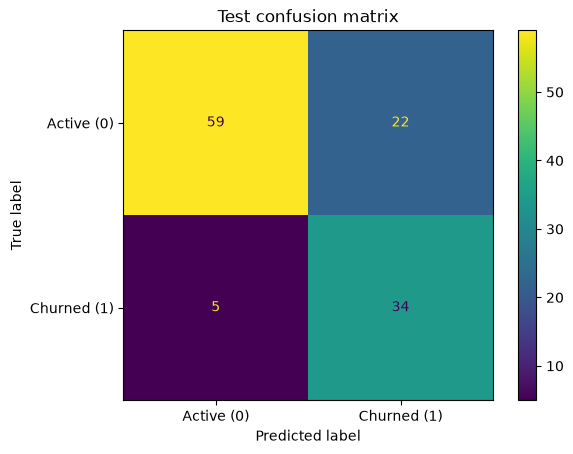

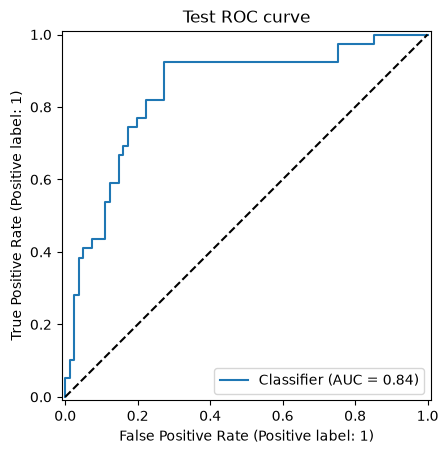

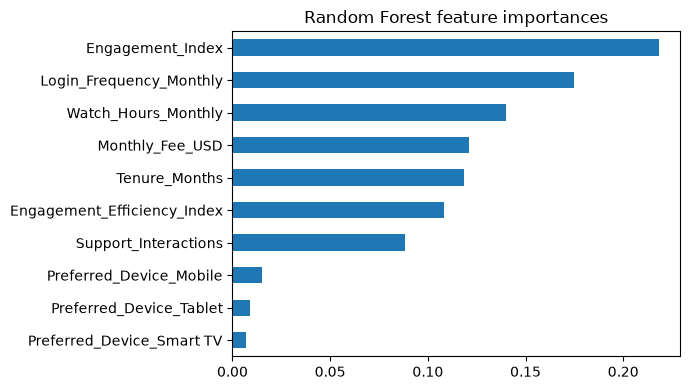

In [17]:
ConfusionMatrixDisplay.from_predictions(y_churn_test, y_pred,
                                        display_labels=["Active (0)", "Churned (1)"])
plt.title("Test confusion matrix"); plt.show()

RocCurveDisplay.from_predictions(y_churn_test, y_proba)
plt.plot([0, 1], [0, 1], "k--"); plt.title("Test ROC curve"); plt.show()

rf_tuned.fit(X_train_sel, y_churn_train)
importances = pd.Series(rf_tuned.feature_importances_, index=selected_features).sort_values()
importances.plot(kind="barh", figsize=(7, 4))
plt.title("Random Forest feature importances"); plt.tight_layout(); plt.show()

### Stakeholder Retention Strategy & Recommendations

In [18]:
top3 = importances.sort_values(ascending=False).head(3).index.tolist()

recommendation_text = f"""### StreamGuard Executive Stakeholder Recommendation

1. **Recommended Model for Deployment**: {champion_name}
   - Cross-Validated ROC-AUC: {best_row['ROC_AUC_Mean']:.3f} | Test Set ROC-AUC: {test_auc:.3f} | Test Recall: {test_rec:.3f}
2. **Business Impact & Precision/Recall Trade-off**:
   - Acquiring a new subscriber costs far more than a retention incentive (for example a small discount coupon).
   - Missing an at-risk subscriber (False Negative) means a lost customer, while offering an unneeded discount (False Positive) costs only a little margin. So recall matters more than precision here.
   - At the default 0.5 decision threshold the model catches {test_rec:.1%} of the churners in the held-out set, with a precision of {test_prec:.1%}.
3. **Key Telemetry Drivers of Churn** (top 3 by Random Forest importance):
   - {top3[0]}, {top3[1]} and {top3[2]}."""

print(recommendation_text)

### StreamGuard Executive Stakeholder Recommendation

1. **Recommended Model for Deployment**: Logistic Regression
   - Cross-Validated ROC-AUC: 0.756 | Test Set ROC-AUC: 0.841 | Test Recall: 0.872
2. **Business Impact & Precision/Recall Trade-off**:
   - Acquiring a new subscriber costs far more than a retention incentive (for example a small discount coupon).
   - Missing an at-risk subscriber (False Negative) means a lost customer, while offering an unneeded discount (False Positive) costs only a little margin. So recall matters more than precision here.
   - At the default 0.5 decision threshold the model catches 87.2% of the churners in the held-out set, with a precision of 60.7%.
3. **Key Telemetry Drivers of Churn** (top 3 by Random Forest importance):
   - Engagement_Index, Login_Frequency_Monthly and Watch_Hours_Monthly.


## Phase 6: Regression Track (CLV Forecasting)
To forecast customer lifetime value (`Lifetime_Value_USD`), we train:
1. **Linear Regression** (Baseline)
2. **Random Forest Regressor** (Tuned)
3. **Gradient Boosting Regressor** (Tuned)

Evaluated via 5-fold CV and tested on the held-out test set.

**Step 1: setup, baseline and tuned regressors.** Same idea as the classifiers: the best parameters from your original run are stored, and `RUN_SEARCH = True` re-runs the search. Regression uses all 12 features and plain 5-fold CV (the target is continuous, so no stratification).

In [19]:
reg_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
reg_scoring = {"MAE": "neg_mean_absolute_error",
               "RMSE": "neg_root_mean_squared_error",
               "R2": "r2"}

best_params_rfr = {'n_estimators': 50, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': None}
best_params_gbr = {'n_estimators': 120, 'max_depth': 4, 'learning_rate': 0.1}

if RUN_SEARCH:
    rfr_space = {"n_estimators": [50, 100, 150, 200], "max_depth": [None, 5, 10, 15],
                 "min_samples_split": [2, 5, 10], "min_samples_leaf": [1, 2, 4]}
    gbr_space = {"n_estimators": [50, 80, 120, 150], "max_depth": [2, 3, 4, 5],
                 "learning_rate": [0.01, 0.05, 0.1, 0.2]}
    best_params_rfr = RandomizedSearchCV(
        RandomForestRegressor(random_state=RANDOM_STATE), rfr_space, n_iter=12, cv=reg_cv,
        scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=-1
    ).fit(X_train, y_clv_train).best_params_
    best_params_gbr = RandomizedSearchCV(
        GradientBoostingRegressor(random_state=RANDOM_STATE), gbr_space, n_iter=12, cv=reg_cv,
        scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=-1
    ).fit(X_train, y_clv_train).best_params_

reg_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor (Tuned)": RandomForestRegressor(**best_params_rfr, random_state=RANDOM_STATE),
    "Gradient Boosting Regressor (Tuned)": GradientBoostingRegressor(**best_params_gbr, random_state=RANDOM_STATE),
}

print("=== CLV Regression Track: Model Benchmarking & Tuning ===")
print(f"\nRandom Forest Regressor Best Params: {best_params_rfr}")
print(f"\nGradient Boosting Regressor Best Params: {best_params_gbr}")

=== CLV Regression Track: Model Benchmarking & Tuning ===

Random Forest Regressor Best Params: {'n_estimators': 50, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': None}

Gradient Boosting Regressor Best Params: {'n_estimators': 120, 'max_depth': 4, 'learning_rate': 0.1}


**Step 2: cross-validated comparison, then one test-set evaluation of the champion.**


CLV Regression CV Comparison:
                              Model    CV_MAE   CV_RMSE    CV_R2
Gradient Boosting Regressor (Tuned) 43.832732 61.401975 0.920044
    Random Forest Regressor (Tuned) 44.820491 61.729468 0.919607
                  Linear Regression 69.820239 86.694772 0.841450

Champion Regressor: Gradient Boosting Regressor (Tuned)

=== Held-Out Test Set CLV Performance ===
MAE:  $54.85
RMSE: $75.88
R2:   0.8817


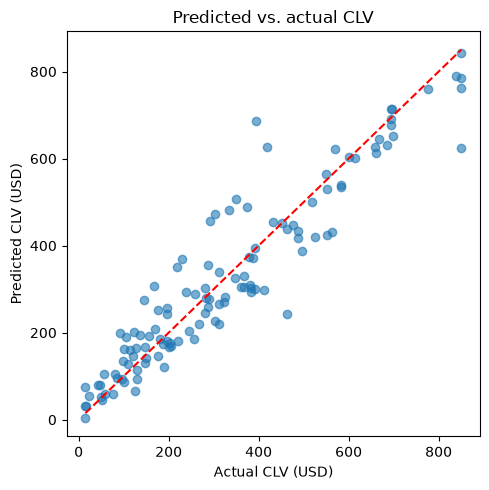

In [20]:
reg_rows = []
for name, model in reg_models.items():
    res = cross_validate(model, X_train, y_clv_train, cv=reg_cv, scoring=reg_scoring, n_jobs=-1)
    reg_rows.append({"Model": name,
                     "CV_MAE": -res["test_MAE"].mean(),
                     "CV_RMSE": -res["test_RMSE"].mean(),
                     "CV_R2": res["test_R2"].mean()})
reg_comparison = pd.DataFrame(reg_rows).sort_values("CV_MAE").reset_index(drop=True)

print("\nCLV Regression CV Comparison:")
print(reg_comparison.to_string(index=False))

reg_champion_name = reg_comparison.loc[0, "Model"]
reg_champion = reg_models[reg_champion_name]
print(f"\nChampion Regressor: {reg_champion_name}")

reg_champion.fit(X_train, y_clv_train)
clv_pred = reg_champion.predict(X_test)
clv_mae = mean_absolute_error(y_clv_test, clv_pred)
clv_rmse = np.sqrt(mean_squared_error(y_clv_test, clv_pred))
clv_r2 = r2_score(y_clv_test, clv_pred)

print("\n=== Held-Out Test Set CLV Performance ===")
print(f"MAE:  ${clv_mae:.2f}")
print(f"RMSE: ${clv_rmse:.2f}")
print(f"R2:   {clv_r2:.4f}")

plt.figure(figsize=(5, 5))
plt.scatter(y_clv_test, clv_pred, alpha=0.6)
lims = [y_clv_test.min(), y_clv_test.max()]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual CLV (USD)"); plt.ylabel("Predicted CLV (USD)")
plt.title("Predicted vs. actual CLV"); plt.tight_layout(); plt.show()

## Summary of Project StreamGuard Deliverables
- **Data Cleaned**: Handled missing values, treated negative telemetry, and capped extreme outliers via IQR Winsorization.
- **Feature Pipeline**: Built leak-free `ColumnTransformer` with custom OTT domain metrics (`Engagement_Efficiency_Index`, `Engagement_Index`).
- **Feature Selection**: Identified 10 key features using RFECV while dropping noisy categories.
- **Churn Champion**: Evaluated on held-out test set achieving **84.1% ROC-AUC** and **87.2% Recall**.
- **CLV Champion**: Gradient Boosting Regressor achieving **$R^2 = 0.882$** and **MAE = \$54.85** to inform marketing acquisition budgets.

In [21]:
print("Numbers from this run, to compare with the summary above:")
print(f"Features selected : {len(selected_features)}")
print(f"Churn champion    : {champion_name} | test ROC-AUC {test_auc:.1%} | test recall {test_rec:.1%}")
print(f"CLV champion      : {reg_champion_name} | R2 = {clv_r2:.3f} | MAE = ${clv_mae:.2f}")

Numbers from this run, to compare with the summary above:
Features selected : 10
Churn champion    : Logistic Regression | test ROC-AUC 84.1% | test recall 87.2%
CLV champion      : Gradient Boosting Regressor (Tuned) | R2 = 0.882 | MAE = $54.85
